SPDX-FileCopyrightText: Copyright (c) 2025 NVIDIA CORPORATION & AFFILIATES. All rights reserved. <br>
SPDX-License-Identifier: Apache-2.0 <br>

Licensed under the Apache License, Version 2.0 (the "License"); <br>
you may not use this file except in compliance with the License. <br>
You may obtain a copy of the License at <br>

http://www.apache.org/licenses/LICENSE-2.0  

Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, <br>
WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. <br>
See the License for the specific language governing permissions and <br>
limitations under the License. 

In [4]:
import time

import torch
from torch import nn

from warpkan.torch_ext.kan import KAN
from warpkan.torch_ext.kanlinear import KANLinear




In [2]:


class GaussianSmearing(nn.Module):
    def __init__(self, start=0.0, stop=5.0, num_gaussians=50, fixed_offset=True):
        super(GaussianSmearing, self).__init__()
        self.start = start
        self.stop = stop
        self.num_gaussians = num_gaussians
        if fixed_offset:  # customized offset
            offset = torch.tensor([0, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75, 3, 3.5, 4, 4.5, 5, 5.5, 6, 7, 8, 9, 10])
        else:
            offset = torch.linspace(start, stop, num_gaussians)
        self.coeff = -0.5 / (offset[1] - offset[0]).item() ** 2
        self.register_buffer('offset', offset)

    def __repr__(self):
        return f'GaussianSmearing(start={self.start}, stop={self.stop}, num_gaussians={self.num_gaussians})'

    def forward(self, dist):
        dist = dist.view(-1, 1) - self.offset.view(1, -1)
        return torch.exp(self.coeff * torch.pow(dist, 2))

In [5]:
in_dim = out_dim = 1
mlp_hidden = 24
grid_num = 20
kan = nn.Sequential(KANLinear(in_dim, 3, 3, grid_num, [0, 10], has_mlp=False), KANLinear(3, out_dim, 3, grid_num, [-10, 10], has_mlp=False)).cuda()
mlp = nn.Sequential(GaussianSmearing(), nn.Linear(20, 1)).cuda()

In [6]:
x = 10*torch.rand(1024, in_dim).cuda()
x_val = 10*torch.rand(1024, in_dim).cuda()
f = lambda x: torch.sin(x * freq) * torch.exp(-x/5)
freq = 5.0
target = f( x)

target_val = f( x_val)

In [7]:
for model in [kan, mlp]:
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
    print(model)
    
    for epoch in range(10000):
        optimizer.zero_grad()
        y = model(x)
        loss = torch.mean((target-y)**2)
        loss.backward()
        optimizer.step()
        if epoch % 500 == 0:
            if epoch == 0:
                print(f"{'epoch':5} | {'train_loss':12} | {'val_loss':12}")    
            print(f"{epoch:5} | {loss.item():0.10f} | {torch.mean((target_val- model(x_val))**2).item():0.10f}")

Sequential(
  (0): KANLinear(
    (bspline): BSpline()
  )
  (1): KANLinear(
    (bspline): BSpline()
  )
)


/home/amoradzadeh/anaconda3/envs/wpKAN/lib/python3.11/site-packages/warp/torch.py:214: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at aten/src/ATen/core/TensorBody.h:489.)
  if t.grad is None:


epoch | train_loss   | val_loss    
    0 | 0.1270199716 | 0.1192523465
  500 | 0.0000174716 | 0.0000211113
 1000 | 0.0000118481 | 0.0000138683
 1500 | 0.0000085845 | 0.0000097962
 2000 | 0.0000229280 | 0.0000336941
 2500 | 0.0000054562 | 0.0000069884
 3000 | 0.0000145871 | 0.0000084986
 3500 | 0.0000036529 | 0.0000041689
 4000 | 0.0000031888 | 0.0000036181
 4500 | 0.0000028096 | 0.0000031609
 5000 | 0.0000024496 | 0.0000027217
 5500 | 0.0000020796 | 0.0000022801
 6000 | 0.0000017294 | 0.0000018886
 6500 | 0.0000014337 | 0.0000015576
 7000 | 0.0000012225 | 0.0000013131
 7500 | 0.0000010373 | 0.0000011316
 8000 | 0.0000009100 | 0.0000010068
 8500 | 0.0000008252 | 0.0000009296
 9000 | 0.0000007660 | 0.0000008665
 9500 | 0.0000007253 | 0.0000008285
Sequential(
  (0): GaussianSmearing(start=0.0, stop=5.0, num_gaussians=50)
  (1): Linear(in_features=20, out_features=1, bias=True)
)
epoch | train_loss   | val_loss    
    0 | 0.1562763751 | 0.1466763020
  500 | 0.1090434790 | 0.1095759124
 1

In [8]:
x = torch.randn(2**16, in_dim).cuda()


In [9]:
torch.cuda.synchronize()
s = time.perf_counter()
for _ in range(10000):
    kan(x)    
torch.cuda.synchronize()

e = time.perf_counter()
print(f"dt_kan {e-s}")

dt_kan 4.213811370078474


In [10]:
torch.cuda.synchronize()
s = time.perf_counter()
for _ in range(10000):
    mlp(x)    
torch.cuda.synchronize()

e = time.perf_counter()
print(f"dt_mlp {e-s}")

dt_mlp 0.7479648939333856


In [11]:
import matplotlib.pyplot as plt
x = torch.linspace(0, 10, 200).reshape(-1, 1).cuda()
y = f(x)
yk = kan(x)
ym = mlp(x)

/home/amoradzadeh/anaconda3/envs/wpKAN/lib/python3.11/site-packages/warp/torch.py:214: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at aten/src/ATen/core/TensorBody.h:489.)
  if t.grad is None:


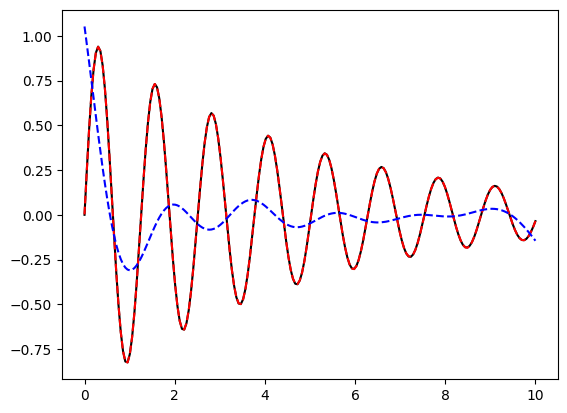

In [12]:
plt.plot(x.cpu().numpy().reshape(-1), y.detach().cpu().numpy(), 'k-')
plt.plot(x.cpu().numpy().reshape(-1), yk.detach().cpu().numpy(), 'r--')
plt.plot(x.cpu().numpy().reshape(-1), ym.detach().cpu().numpy(), 'b--')
plt.show()